# Differential equations 4: Laplace transforms, switches and hammer blows

*Learning path: differential equations, part 4 of 8.* [Index](README.md) · Previous: [Second-order equations](03-second-order.ipynb) · Next: [Systems and the phase plane](05-systems-and-phase-plane.ipynb)

An engineer switches a motor on at $t = 1$ and off at $t = 3$. A hammer strikes a bell. A circuit gets a voltage spike.
The forcing in these problems jumps or acts in an instant, and the guesses of lesson 3 do not fit. The **Laplace
transform** handles them all with one recipe: it turns a differential equation into an algebra problem in a new
variable $s$, which you solve, and then turn back. Oliver Heaviside used it to design telegraph lines before
mathematicians could justify it; today every control engineer's "transfer function" is a Laplace transform.

**Who this is for.** You have done [lesson 3](03-second-order.ipynb) and can integrate by parts. Partial fractions
are explained here.

**What you will be able to do afterwards:**

1. compute Laplace transforms from the definition and from a table, and use the shift rules;
2. solve an initial value problem by transforming, solving for $Y(s)$ and inverting with partial fractions;
3. write a switched force with the step function and solve the resulting equation;
4. model an instantaneous blow with the Dirac delta, and read off the impulse response and transfer function.

Plan about an hour and a half.

## 1. The transform

The Laplace transform of a function $f(t)$, $t \ge 0$, is

$$F(s) = \mathcal{L}\{f\}(s) = \int_0^\infty f(t)\,e^{-st}\,dt.$$

The integral converges when $s$ is large enough, so we tell Galileo that $s > 0$ with `assume`. Then the definition can
be evaluated directly:

In [1]:
assume(s > 0)
int(exp(-s*t), t, 0, inf)
int(t*exp(-s*t), t, 0, inf)
int(sin(t)*exp(-s*t), t, 0, inf)

"s > 0"

> Assumptions now: s > 0. They decide signs in limits and integrals (e^(-a t) → 0 as t → ∞ when a > 0, sqrt(a²) = a) and simplify sin(nπ) = 0, cos(nπ) = (−1)^n for an integer n. forget(a) removes them.

1/s

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

1/s^2

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

1/(s^2+1)

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

`laplace` uses a table and rules instead of integrating every time. The basic pairs, with the rules that extend them:

| $f(t)$ | $F(s)$ | rule |
|---|---|---|
| $1$, $t^n$ | $1/s$, $n!/s^{n+1}$ | |
| $e^{at}$ | $1/(s - a)$ | $e^{at}f(t) \mapsto F(s - a)$ (shift in $s$) |
| $\cos bt$, $\sin bt$ | $s/(s^2 + b^2)$, $b/(s^2 + b^2)$ | $t\,f(t) \mapsto -F'(s)$ |
| $y'(t)$, $y''(t)$ | $sY - y(0)$, $s^2Y - sy(0) - y'(0)$ | derivatives become multiplication by $s$ |

In [2]:
laplace(cos(w*t), t, s)
laplace(t^2*exp(3*t), t, s)
laplace(exp(-t)*sin(t)*t, t, s)

s/(s^2+w^2)

> L{f}(s) = ∫₀^∞ f(t) e^(−st) dt, from the table: L{1} = 1/s, L{t^n} = n!/s^(n+1), L{e^(at)} = 1/(s − a), L{sin(bt)} = b/(s² + b²), L{cos(bt)} = s/(s² + b²), and the rules e^(at)f ↦ F(s − a), t·f ↦ −F′(s), heaviside(t − a)f(t − a) ↦ e^(−as)F(s), L{y′} = sY − y(0). Valid for s large enough that the integral converges.

2/(s-3)^3

> L{f}(s) = ∫₀^∞ f(t) e^(−st) dt, from the table: L{1} = 1/s, L{t^n} = n!/s^(n+1), L{e^(at)} = 1/(s − a), L{sin(bt)} = b/(s² + b²), L{cos(bt)} = s/(s² + b²), and the rules e^(at)f ↦ F(s − a), t·f ↦ −F′(s), heaviside(t − a)f(t − a) ↦ e^(−as)F(s), L{y′} = sY − y(0). Valid for s large enough that the integral converges.

2*(s+1)/((s+1)^2+1)^2

> L{f}(s) = ∫₀^∞ f(t) e^(−st) dt, from the table: L{1} = 1/s, L{t^n} = n!/s^(n+1), L{e^(at)} = 1/(s − a), L{sin(bt)} = b/(s² + b²), L{cos(bt)} = s/(s² + b²), and the rules e^(at)f ↦ F(s − a), t·f ↦ −F′(s), heaviside(t − a)f(t − a) ↦ e^(−as)F(s), L{y′} = sY − y(0). Valid for s large enough that the integral converges.

The last row is the reason for all of this: by parts, $\int_0^\infty y'e^{-st}dt = [ye^{-st}]_0^\infty +
s\int_0^\infty ye^{-st}dt = sY - y(0)$. **Differentiation in $t$ becomes multiplication by $s$**, and the start values
come along automatically.

**Try this.** Compute $\mathcal L\{e^{3t}\}$ from the definition by hand. For which $s$ does the integral converge?

## 2. Solving an initial value problem

Solve $y'' + 3y' + 2y = 1$ with $y(0) = 1$, $y'(0) = 0$. Transform both sides; write `y(t)`, `d(y, t)` and `d(y, t, 2)` so that
`laplace` knows $y$ is the unknown function:

In [3]:
laplace(d(y, t, 2) + 3*d(y, t) + 2*y(t), t, s)

s^2*Y(s)+3*s*Y(s)-s*y(0)+2*Y(s)-3*y(0)-d(y, 0)

> L{f}(s) = ∫₀^∞ f(t) e^(−st) dt, from the table: L{1} = 1/s, L{t^n} = n!/s^(n+1), L{e^(at)} = 1/(s − a), L{sin(bt)} = b/(s² + b²), L{cos(bt)} = s/(s² + b²), and the rules e^(at)f ↦ F(s − a), t·f ↦ −F′(s), heaviside(t − a)f(t − a) ↦ e^(−as)F(s), L{y′} = sY − y(0). Valid for s large enough that the integral converges.

With $y(0) = 1$, $y'(0) = 0$ and $\mathcal L\{1\} = 1/s$, the differential equation has become an **algebraic**
equation for $Y$:

$$s^2Y - s + 3(sY - 1) + 2Y = \frac1s.$$

In [4]:
Y = solve(s^2*Y - s + 3*(s*Y - 1) + 2*Y == 1/s, Y)
partfrac(Y, s)

(s^2+3*s+1)/(s*(s^2+3*s+2))

> Linear: Y = −b/a = `(s^2+3*s+1)/(s*(s^2+3*s+2))`.

1/(2*s)+1/(s+1)-1/(2*(s+2))

> Partial fractions: the denominator is factored over the rationals and f is written as a polynomial plus one fraction per factor (and per power of a repeated factor), with constant numerators over linear factors and linear numerators over quadratic ones.

Partial fractions split $Y$ into pieces that are in the table: $\frac{1}{2s} \mapsto \frac12$,
$\frac{1}{s + 1} \mapsto e^{-t}$, $\frac{-1/2}{s + 2} \mapsto -\frac12e^{-2t}$. `ilaplace` does these steps, and
`dsolve` agrees:

In [5]:
ilaplace(Y, s, t)
dsolve(d(y, t, 2) + 3*d(y, t) + 2*y == 1, y, t, 0, [1, 0])

exp(-t)-exp(-2*t)/2+1/2

> Inverse transform: split F into partial fractions (1/(2*s)+1/(s+1)-1/(2*(s+2))), then read each piece backwards from the table: c/(s − r)^n ↦ c t^(n−1) e^(rt)/(n−1)!, quadratic factors ↦ e^(at) cos and sin, and a factor e^(−as) delays the piece to start at t = a (heaviside).

exp(-t)-exp(-2*t)/2+1/2

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

The method never needed a guess, and the start values were built in from the beginning.

**Try this.** Invert $\dfrac{2s + 3}{s^2 + 4s + 13}$. Complete the square: $s^2 + 4s + 13 = (s + 2)^2 + 9$, then use
the shift rule.

In [6]:
ilaplace((2*s + 3)/(s^2 + 4*s + 13), s, t)

exp(-2*t)*(2*cos(3*t)-sin(3*t)/3)

> Inverse transform: split F into partial fractions ((2*s+3)/(s^2+4*s+13)), then read each piece backwards from the table: c/(s − r)^n ↦ c t^(n−1) e^(rt)/(n−1)!, quadratic factors ↦ e^(at) cos and sin, and a factor e^(−as) delays the piece to start at t = a (heaviside).

## 3. Switches: the Heaviside step

The **unit step** `heaviside(t - a)` is 0 before $t = a$ and 1 after. A force that is on between $t = 1$ and $t = 3$
is `heaviside(t - 1) - heaviside(t - 3)`. Its transform uses the **shift in $t$** rule: delaying a function by $a$
multiplies its transform by $e^{-as}$,

$$\mathcal L\{\text{heaviside}(t - a)\,f(t - a)\} = e^{-as}F(s).$$

In [7]:
laplace(heaviside(t - 1) - heaviside(t - 3), t, s)

exp(-s)/s-exp(-3*s)/s

> L{f}(s) = ∫₀^∞ f(t) e^(−st) dt, from the table: L{1} = 1/s, L{t^n} = n!/s^(n+1), L{e^(at)} = 1/(s − a), L{sin(bt)} = b/(s² + b²), L{cos(bt)} = s/(s² + b²), and the rules e^(at)f ↦ F(s − a), t·f ↦ −F′(s), heaviside(t − a)f(t − a) ↦ e^(−as)F(s), L{y′} = sY − y(0). Valid for s large enough that the integral converges.

Push a spring $y'' + 4y = f(t)$ from rest with this force. Transforming gives $(s^2 + 4)Y = (e^{-s} - e^{-3s})/s$:

heaviside(t-3)*(cos(2*(t-3))-1)/4+heaviside(t-1)*(1/4-cos(2*(t-1))/4)

> Inverse transform: split F into partial fractions, then read each piece backwards from the table: c/(s − r)^n ↦ c t^(n−1) e^(rt)/(n−1)!, quadratic factors ↦ e^(at) cos and sin, and a factor e^(−as) delays the piece to start at t = a (heaviside).

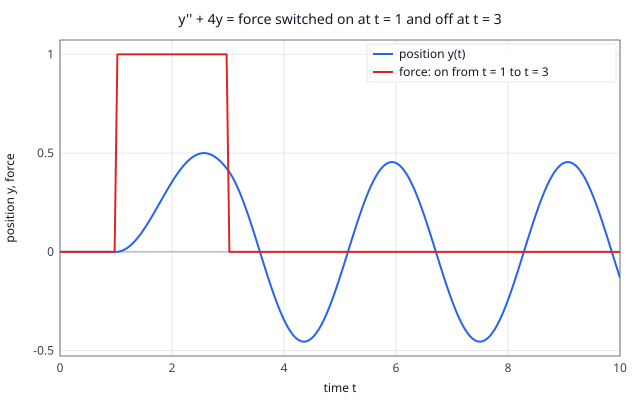

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [8]:
y = ilaplace((exp(-s) - exp(-3*s))/(s*(s^2 + 4)), s, t)
p = plot(y, heaviside(t - 1) - heaviside(t - 3), t, 0, 10);
p = legend(p, "position y(t)", "force: on from t = 1 to t = 3");
labels(title(p, "y'' + 4y = force switched on at t = 1 and off at t = 3"), "time t", "position y, force")

While the force is on, the spring oscillates around the new rest position $1/4$; after it switches off, it oscillates
around 0 with whatever energy it has. Each `heaviside` factor in the answer marks the moment a new piece starts.

**Try this.** What happens if the force is switched off at $t = 1 + \pi$, a whole period later? Change the 3 and look.
(The spring ends at rest.)

## 4. Hammer blows: the Dirac delta and the transfer function

A hammer delivers a large force for a very short time; only the total impulse $\int F\,dt$ matters. The idealization is
the **Dirac delta** $\delta(t - a)$: zero except at $t = a$, with $\int \delta(t - a)\,dt = 1$. It picks out a value:

$$\int h(t)\,\delta(t - a)\,dt = h(a).$$

In [9]:
int(dirac(t - 2)*cos(t), t, 0, 5)
laplace(dirac(t - 1), t, s)

cos(2)

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

exp(-s)

> L{f}(s) = ∫₀^∞ f(t) e^(−st) dt, from the table: L{1} = 1/s, L{t^n} = n!/s^(n+1), L{e^(at)} = 1/(s − a), L{sin(bt)} = b/(s² + b²), L{cos(bt)} = s/(s² + b²), and the rules e^(at)f ↦ F(s − a), t·f ↦ −F′(s), heaviside(t − a)f(t − a) ↦ e^(−as)F(s), L{y′} = sY − y(0). Valid for s large enough that the integral converges.

Strike a damped spring $y'' + 2y' + 5y = \delta(t - 1)$ at rest. Then $(s^2 + 2s + 5)Y = e^{-s}$:

exp(-(t-1))*sin(2*(t-1))*heaviside(t-1)/2

> Inverse transform: split F into partial fractions, then read each piece backwards from the table: c/(s − r)^n ↦ c t^(n−1) e^(rt)/(n−1)!, quadratic factors ↦ e^(at) cos and sin, and a factor e^(−as) delays the piece to start at t = a (heaviside).

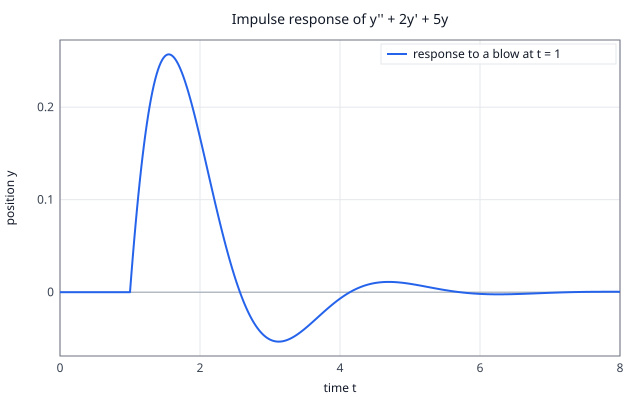

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [10]:
blow = ilaplace(exp(-s)/(s^2 + 2*s + 5), s, t)
p = plot(blow, t, 0, 8);
p = legend(p, "response to a blow at t = 1");
labels(title(p, "Impulse response of y'' + 2y' + 5y"), "time t", "position y")

Nothing happens until $t = 1$; then the spring starts with a sudden velocity 1 and rings down. This **impulse
response** $h(t) = e^{-t}\sin(2t)/2$ (for a blow at $t = 0$) characterizes the system completely: its transform
$H(s) = 1/(s^2 + 2s + 5)$ is the **transfer function**, and for any force $f$ starting from rest,
$Y(s) = H(s)F(s)$. Engineers design filters, controllers and loudspeakers by shaping $H(s)$; its poles
$s = -1 \pm 2i$ are the characteristic roots of lesson 3.

**Try this.** Strike the undamped spring $y'' + y = \delta(t - 2)$. Predict the answer before running
`ilaplace(exp(-2*s)/(s^2 + 1), s, t)`.

In [11]:
ilaplace(exp(-2*s)/(s^2 + 1), s, t)
forget(s);

sin(t-2)*heaviside(t-2)

> Inverse transform: split F into partial fractions, then read each piece backwards from the table: c/(s − r)^n ↦ c t^(n−1) e^(rt)/(n−1)!, quadratic factors ↦ e^(at) cos and sin, and a factor e^(−as) delays the piece to start at t = a (heaviside).

## Summary

* $\mathcal L\{f\} = \int_0^\infty fe^{-st}dt$. Derivatives become multiplication by $s$, with the start values built
  in: $\mathcal L\{y'\} = sY - y(0)$.
* Recipe: transform, solve the algebra for $Y(s)$, split into partial fractions, invert from the table.
* Shifts: $e^{at}f \mapsto F(s - a)$, and a delay by $a$ multiplies by $e^{-as}$.
* Switches are differences of steps; blows are deltas, with $\int h\,\delta(t - a) = h(a)$.
* Transfer function $H(s)$: the transform of the impulse response, and $Y = HF$ from rest.

Next: [systems of equations and the phase plane](05-systems-and-phase-plane.ipynb).

## Exercises

1. **Table.** Find $\mathcal L\{\sin^2 t\}$ using $\sin^2 t = (1 - \cos 2t)/2$, and check with `laplace`.
2. **IVP.** Solve $y'' - y = e^{2t}$, $y(0) = 0$, $y'(0) = 1$ by Laplace transform. Show the partial fractions.
3. **Ramp.** A force grows linearly from $t = 2$ on: $f(t) = (t - 2)\,\text{heaviside}(t - 2)$. Find its transform.
4. **Two blows.** Solve $y'' + y = \delta(t) - \delta(t - \pi)$ from rest. What happens after $t = \pi$, and why?
5. **Square root.** Find $\mathcal L\{\sqrt t\}$. (It needs the gamma function: $\Gamma(3/2) = \sqrt\pi/2$.)

## Hints and answers

* **Section 1, Try this.** $\int_0^\infty e^{(3 - s)t}dt = 1/(s - 3)$, converging for $s > 3$.
* **Section 2, Try this.** $\frac{2(s + 2) - 1}{(s + 2)^2 + 9} \mapsto e^{-2t}(2\cos 3t - \tfrac13\sin 3t)$.
* **Section 3, Try this.** $y$ is $\frac14(1 - \cos 2(t - 1))$ while the force acts, and at $t = 1 + \pi$ both $y$ and
  $y'$ are back to 0, so the spring stays at rest.
* **Section 4, Try this.** $\sin(t - 2)\,\text{heaviside}(t - 2)$: at rest until the blow, then a sine with
  velocity 1.
* **Exercise 1.** $\frac{1}{2s} - \frac{s}{2(s^2 + 4)} = \frac{2}{s(s^2 + 4)}$.
* **Exercise 2.** $(s^2 - 1)Y - 1 = \frac{1}{s - 2}$, so $Y = \frac{s - 1}{(s - 2)(s^2 - 1)} =
  \frac{1}{(s - 2)(s + 1)} = \frac{1/3}{s - 2} - \frac{1/3}{s + 1}$ and $y = (e^{2t} - e^{-t})/3$.
* **Exercise 3.** $e^{-2s}/s^2$.
* **Exercise 4.** $Y = (1 - e^{-\pi s})/(s^2 + 1)$, $y = \sin t - \sin(t - \pi)\,\text{heaviside}(t - \pi)$, which
  is $2\sin t$ after $t = \pi$: the second blow comes in phase and doubles the motion.
* **Exercise 5.** $\sqrt\pi/(2s^{3/2})$.

## Sources

1. W. E. Boyce, R. C. DiPrima and D. B. Meade, *Elementary Differential Equations and Boundary Value Problems*, 11th
   ed., Wiley (2017), chapter 6.
2. O. Heaviside, *Electromagnetic Theory*, vol. 2, The Electrician (1899), chapter 7 (operational calculus).
3. P. A. M. Dirac, *The Principles of Quantum Mechanics*, Oxford (1930), section 15 (the delta function).
4. K. J. Åström and R. M. Murray, *Feedback Systems*, 2nd ed., Princeton University Press (2021), chapter 9
   (transfer functions).